# 03 · What incomplete logs do to the model

The full grid (3 damage types x levels x 5 seeds x strategies x 2 models) is run by `python -m src.experiments`, which writes `results/`. This notebook shows those results and walks through one example of each damage type.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)

In [2]:
from src.experiments import Data, _damage, _handle, STRATEGY_LABELS
from src.evaluate import make_model, metrics, false_alarm_rate
from src.corrupt import activity_cols
results = Path.cwd().parent / 'results'
df = pd.read_csv(results / 'damage_results.csv')
df.head()

,damage,level,seed,strategy,model,auc,pr_auc,recall,precision,f1,false_alarm_rate,tn,fp,fn,tp,false_alarm_affected,false_alarm_unaffected,auc_lo,auc_hi
0,A,0.0,0,naive,logreg,0.717860,0.672738,0.571015,0.631343,0.599666,0.261319,6510,2303,2963,3944,NaN,0.261319,0.709672,0.725068
1,A,0.0,0,naive,hgb,0.746651,0.704260,0.601419,0.660308,0.629489,0.242483,6676,2137,2753,4154,NaN,0.242483,0.738961,0.754556
2,A,0.0,0,train_damage,logreg,0.717420,0.671157,0.565658,0.633328,0.597583,0.256666,6551,2262,3000,3907,NaN,0.256666,0.709195,0.724478
3,A,0.0,0,train_damage,hgb,0.746360,0.702326,0.593456,0.658474,0.624277,0.241235,6687,2126,2808,4099,NaN,0.241235,0.738381,0.753821
4,A,0.0,1,naive,logreg,0.717860,0.672738,0.571015,0.631343,0.599666,0.261319,6510,2303,2963,3944,NaN,0.261319,NaN,NaN


## AUC as records go missing

Lines are the mean over 5 random seeds; shaded bands are the min-max across seeds.

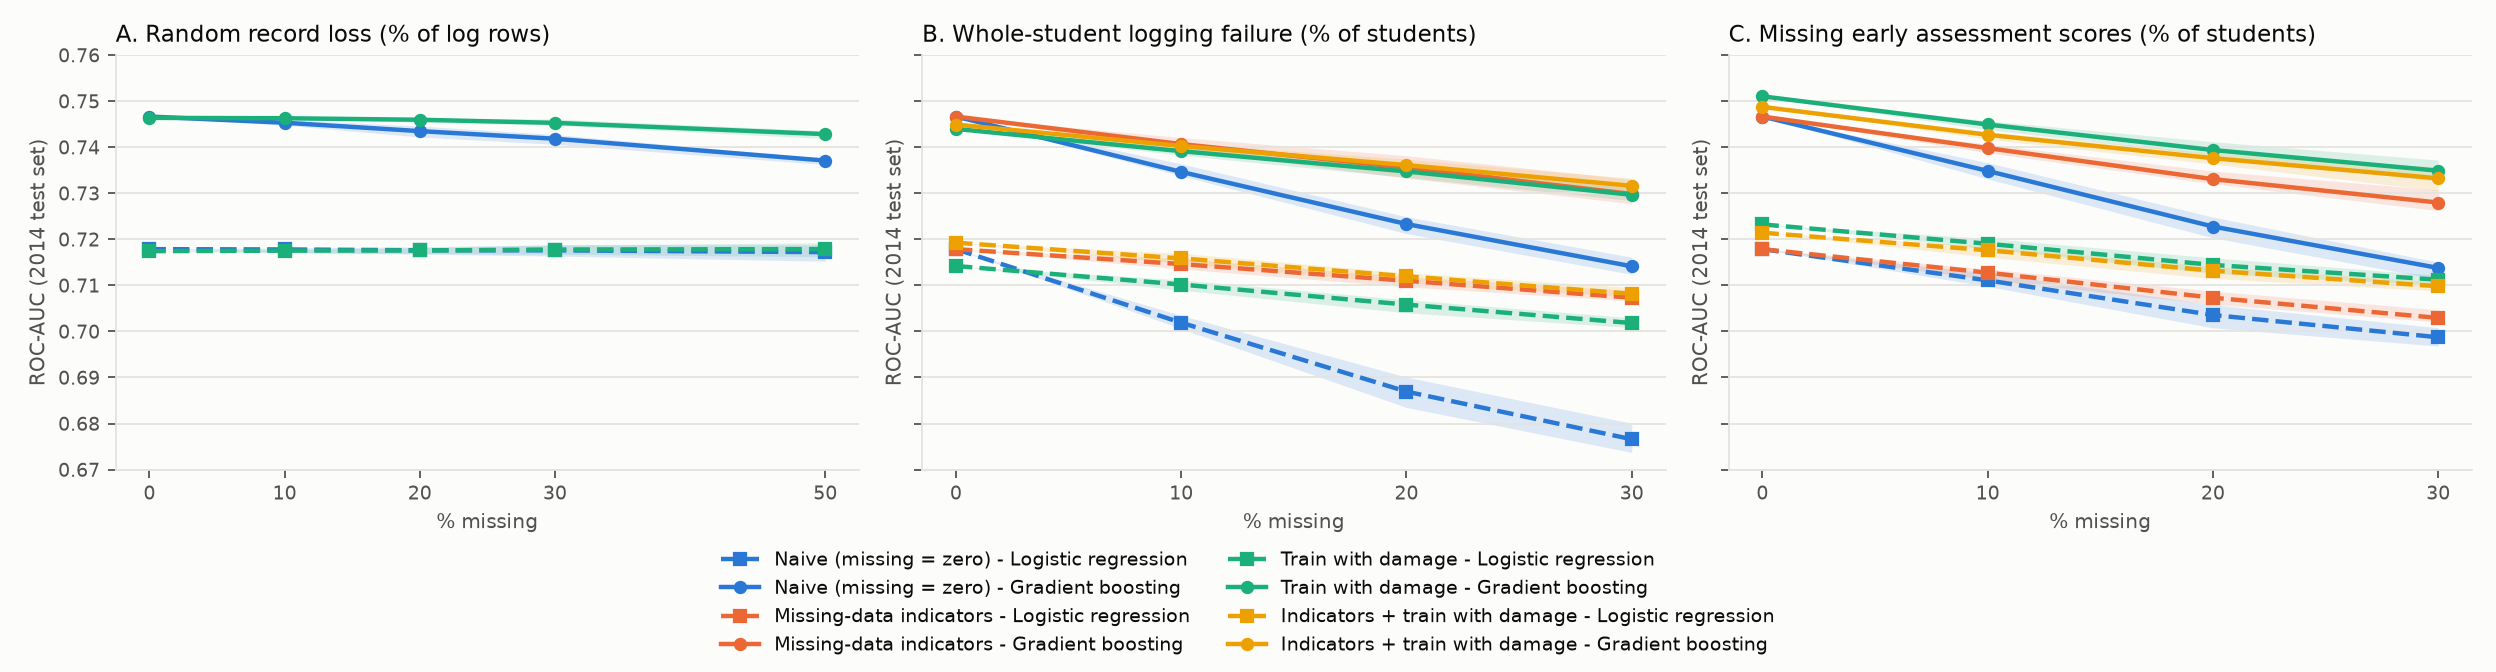

In [3]:
from IPython.display import Image
Image(results / 'auc_vs_missing.png')

## AUC with 95% bootstrap CI at 0% and 30% damage (seed 0)

In [4]:
pd.read_csv(results / 'auc_table.csv')

,damage,strategy,model,AUC at 0%,AUC at 30%,false alarms at 0%,false alarms at 30%,"false alarms, affected students at 30%"
0,A,Naive (missing = zero),Logistic regression,"0.718 [0.710, 0.725]","0.718 [0.710, 0.726]",26.1%,27.3%,-
1,A,Naive (missing = zero),Gradient boosting,"0.747 [0.739, 0.755]","0.743 [0.734, 0.750]",24.2%,26.9%,-
2,A,Train with damage,Logistic regression,"0.717 [0.709, 0.724]","0.718 [0.710, 0.726]",25.7%,26.9%,-
3,A,Train with damage,Gradient boosting,"0.746 [0.738, 0.754]","0.746 [0.738, 0.754]",24.1%,25.6%,-
4,B,Naive (missing = zero),Logistic regression,"0.718 [0.710, 0.725]","0.680 [0.672, 0.688]",26.1%,45.2%,90.8%
5,B,Naive (missing = zero),Gradient boosting,"0.747 [0.739, 0.755]","0.716 [0.708, 0.725]",24.2%,37.1%,67.9%
6,B,Missing-data indicators,Logistic regression,"0.718 [0.710, 0.725]","0.708 [0.699, 0.715]",26.1%,28.7%,34.5%
7,B,Missing-data indicators,Gradient boosting,"0.747 [0.739, 0.755]","0.728 [0.720, 0.736]",24.2%,23.9%,23.1%
8,B,Train with damage,Logistic regression,"0.714 [0.706, 0.721]","0.703 [0.695, 0.710]",26.1%,31.4%,44.3%
9,B,Train with damage,Gradient boosting,"0.744 [0.736, 0.752]","0.729 [0.721, 0.737]",24.4%,25.8%,30.1%


## False alarms

False-alarm rate = share of students who went on to pass but were flagged at risk (threshold 0.5). Measured among the students whose records were lost.

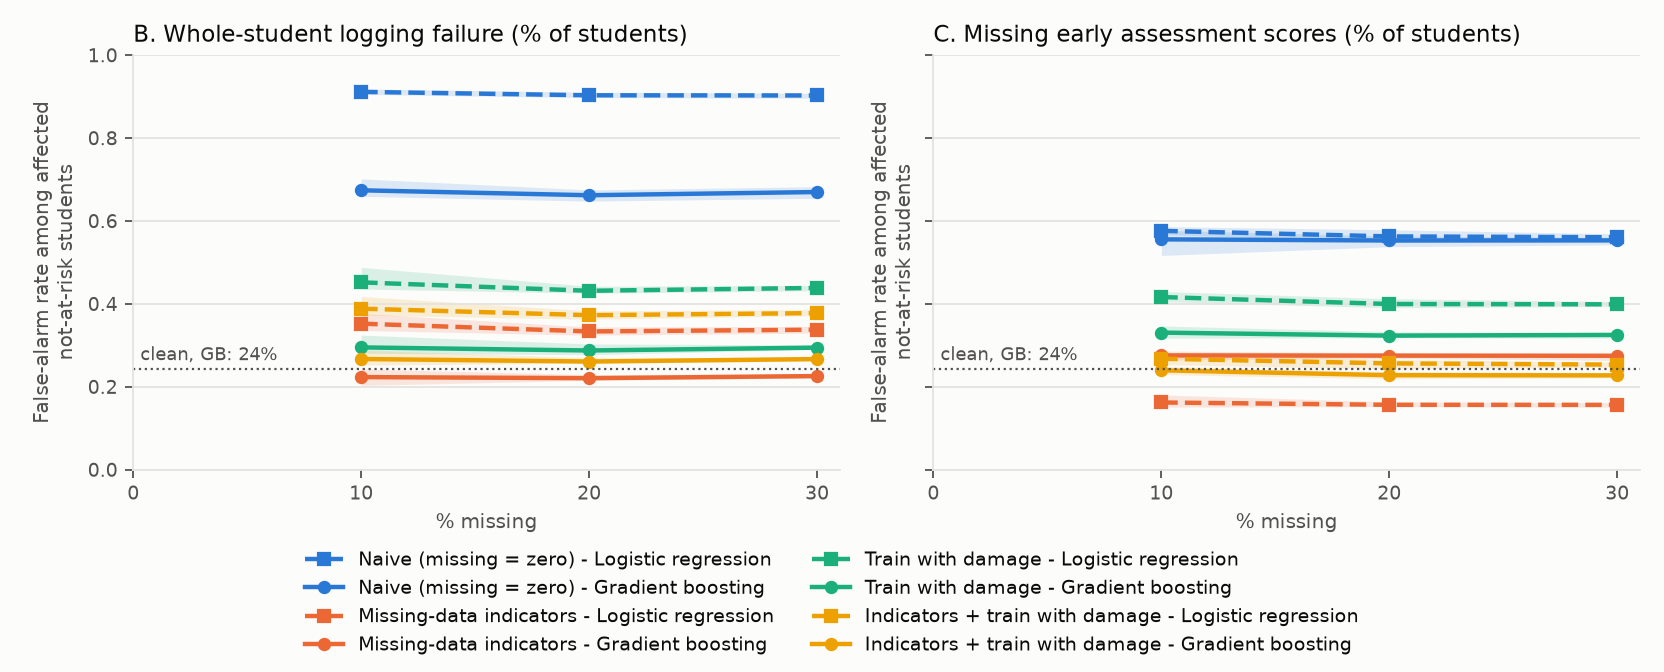

In [5]:
Image(results / 'false_alarms.png')

In [6]:
(df[df['damage'] != 'A'].groupby(['damage', 'model', 'strategy', 'level'])[['auc', 'false_alarm_rate', 'false_alarm_affected', 'false_alarm_unaffected']]
   .mean().round(3).unstack('level')['false_alarm_affected'])

level                                  0.0    0.1    0.2    0.3
damage model  strategy                                         
B      hgb    indicators               NaN  0.223  0.220  0.226
              indicators+train_damage  NaN  0.267  0.261  0.267
              naive                    NaN  0.674  0.662  0.670
              train_damage             NaN  0.295  0.287  0.294
       logreg indicators               NaN  0.352  0.333  0.337
              indicators+train_damage  NaN  0.388  0.372  0.377
              naive                    NaN  0.911  0.903  0.903
              train_damage             NaN  0.452  0.431  0.438
C      hgb    indicators               NaN  0.275  0.275  0.275
              indicators+train_damage  NaN  0.239  0.228  0.227
              naive                    NaN  0.555  0.553  0.553
              train_damage             NaN  0.330  0.323  0.325
       logreg indicators               NaN  0.162  0.156  0.156
              indicators+train_damage  NaN  0.267  0.256  0.253
              naive                    NaN  0.576  0.562  0.561
              train_damage             NaN  0.416  0.399  0.399

## One worked example: damage B at 30%

What a passing student with lost logs looks like to each strategy.

In [7]:
d = Data()
rng = np.random.default_rng(0)
X, mask = _damage(d, 'B', d.vle_test, d.sub_test, d.test_sids, 0.3, rng, d.test)
yte = d.y.loc[d.test_sids].to_numpy()
print(f'{mask.mean():.0%} of 2014 students lost all their logs')
print('total clicks before damage:', d.X.loc[d.test_sids].loc[mask, 'total_clicks'].median(), '(median of affected students)')
print('total clicks after damage: ', X.loc[mask, 'total_clicks'].median())

30% of 2014 students lost all their logs
total clicks before damage: 205.0 (median of affected students)
total clicks after damage:  0.0


In [8]:
Xtr, ytr = d.X.loc[d.train_sids], d.y.loc[d.train_sids]
naive = make_model('hgb', Xtr).fit(Xtr, ytr)
p = naive.predict_proba(X[Xtr.columns])[:, 1]
clean_p = naive.predict_proba(d.X.loc[d.test_sids][Xtr.columns])[:, 1]
print('false alarms among affected passing students, before damage:', round(false_alarm_rate(yte, clean_p, mask), 3))
print('false alarms among affected passing students, after damage: ', round(false_alarm_rate(yte, p, mask), 3))

false alarms among affected passing students, before damage: 0.242
false alarms among affected passing students, after damage:  0.679
